## **02_pytorch_classification_exercises** 

1. Make a binary classification dataset with Scikit-Learn's [`make_moons()`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_moons.html) function.
    * For consistency, the dataset should have 1000 samples and a `random_state=42`.
    * Turn the data into PyTorch tensors. 
	* Split the data into training and test sets using `train_test_split` with 80% training and 20% testing.

In [2]:
# check the device 
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [7]:
from sklearn.datasets import make_moons

# Make 1000 samples 
n_samples = 1000 

# Create circles
X, y = make_moons(
    n_samples= n_samples,
    noise= 0.07,
    random_state= 42
)

In [9]:
# Turn data into tensor 

X = torch.tensor(X, dtype=torch.float32).to(device)
y = torch.tensor(y, dtype=torch.float32).to(device)


C:\Users\User\AppData\Local\Temp\ipykernel_1224\1036051021.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X = torch.tensor(X, dtype=torch.float32).to(device)
C:\Users\User\AppData\Local\Temp\ipykernel_1224\1036051021.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y = torch.tensor(y, dtype=torch.float32).to(device)


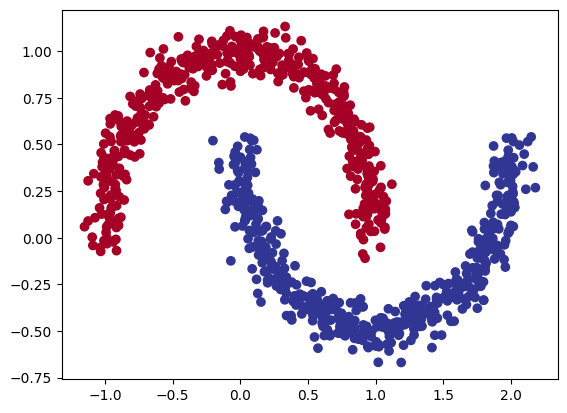

In [12]:
# Let's Visulaze it 
import matplotlib.pyplot as plt 

plt.scatter(X[:,0], X[:,1], c= y , cmap=plt.cm.RdYlBu)
plt.show()

In [14]:
# Split the data into training and test sets using `train_test_split` with 80% training and 20% testing 
from  sklearn.model_selection import train_test_split 

X_train, y_train, X_test, y_test = train_test_split(
    X,
    y,
    test_size= 0.2,
    train_size= 0.8, 
    random_state= 42
)

len(X_train), len(y_train), len(X_test), len(y_test)

(800, 200, 800, 200)

2. Build a model by subclassing `nn.Module` that incorporates non-linear activation functions and is capable of fitting the data you created in 1.
    * Feel free to use any combination of PyTorch layers (linear and non-linear) you want

In [15]:
import torch
from torch import nn

class MoonModelV0(nn.Module):
    def __init__(self, in_features, out_features, hidden_units):
        super().__init__()
        
        self.layer1 = nn.Linear(in_features=in_features, 
                                 out_features=hidden_units)
        self.layer2 = nn.Linear(in_features=hidden_units, 
                                 out_features=hidden_units)
        self.layer3 = nn.Linear(in_features=hidden_units,
                                out_features=out_features)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.layer3(self.relu(self.layer2(self.relu(self.layer1(x)))))

model_0 = MoonModelV0(in_features=2,
                      out_features=1,
                      hidden_units=10).to(device)
model_0

MoonModelV0(
  (layer1): Linear(in_features=2, out_features=10, bias=True)
  (layer2): Linear(in_features=10, out_features=10, bias=True)
  (layer3): Linear(in_features=10, out_features=1, bias=True)
  (relu): ReLU()
)

In [20]:
# Let's see the parameters 

#model_0.state_dict() 
model_0.layer1.state_dict()

OrderedDict([('weight',
              tensor([[ 0.5847,  0.6032],
                      [-0.1230,  0.3552],
                      [-0.6877, -0.0194],
                      [ 0.1182,  0.3572],
                      [-0.1056,  0.1658],
                      [-0.0427, -0.6443],
                      [ 0.1438, -0.5915],
                      [ 0.0952,  0.6070],
                      [ 0.2323, -0.2488],
                      [ 0.1313, -0.2969]])),
             ('bias',
              tensor([-0.1912, -0.5164, -0.6421,  0.1002,  0.4211,  0.1278,  0.4542, -0.0836,
                      -0.5975,  0.1665]))])